# SETUP

In [3]:
import os
import numpy as np
import pynwb
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [4]:
path = '../data/worm-2025-fieseler/allworms/exported_data_gcamp_freely_moving/'
filenames = os.listdir(path)
filename = filenames[10]
nwbfile = pynwb.read_nwb(path + filename)

behavioral_data = nwbfile.processing['Behavior'].data_interfaces
calcium_data = nwbfile.processing['CalciumActivity'].data_interfaces
print(behavioral_data.keys())
print(nwbfile.processing['CalciumActivity'].data_interfaces.keys())

/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


dict_keys(['angular_velocity', 'body_curvature', 'discrete_states', 'eigenworms', 'head_curvature', 'hilbert_amplitude', 'hilbert_carrier', 'hilbert_frequency', 'hilbert_phase', 'kymograph', 'reversal_events', 'stage_position', 'velocity'])
dict_keys(['CalciumSeriesSegmentationCoords', 'NeuronIDs', 'ReferenceFluorescence', 'SignalDFoF', 'SignalFluorescence', 'order_optical_channels'])


## Kymograph bc why not



In [5]:
kymograph = behavioral_data['kymograph'].time_series['kymograph'].data
plt.figure(figsize=(200, 200))
plt.imshow(np.array(kymograph).T, aspect=30, interpolation='nearest', cmap='rainbow')

# Correlation heatmaps

In [6]:
def plot_correlation_heatmap(corr):
	plt.figure(figsize=(12, 6))
	plt.imshow(corr, cmap='viridis', vmin=-1, vmax=1, interpolation='nearest')
	plt.colorbar(label='Correlation')
	plt.title('Neuron-Neuron Correlation Matrix')
	plt.xlabel('Neuron')
	plt.ylabel('Neuron')
	plt.tight_layout()
	plt.show()

In [7]:
signal = np.array(calcium_data['SignalDFoF'].roi_response_series['SignalCalciumImResponseSeries'].data)
#signal = np.array(calcium_data['SignalFluorescence'].roi_response_series['SignalCalciumImResponseSeries'].data)

scaler = StandardScaler()
signal = scaler.fit_transform(signal)

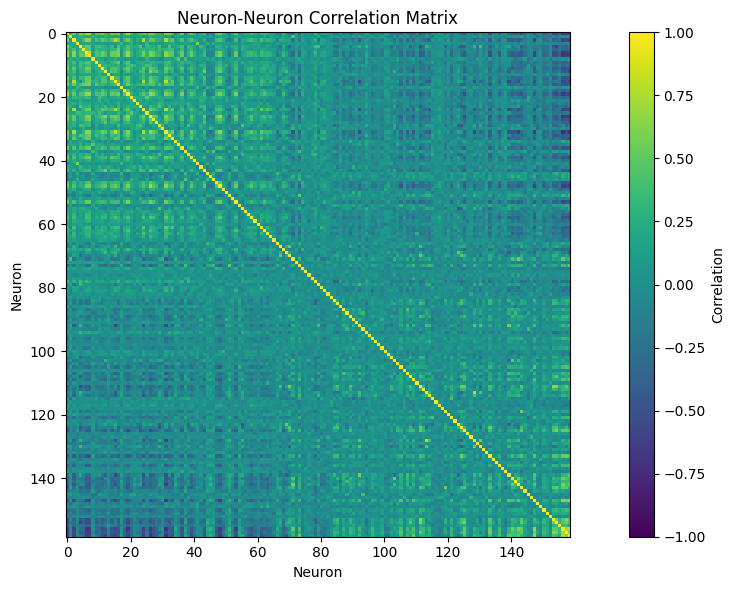

In [8]:
corr = np.corrcoef(signal.T)
corr_sums = np.sum(corr, axis=1)
idxs = np.argsort(corr_sums)[::-1]

corr = corr[idxs][:, idxs]

plot_correlation_heatmap(corr)

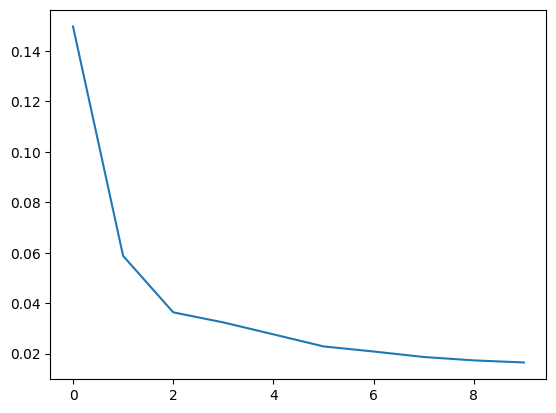

In [9]:
pca_temp = PCA(n_components=10)
sr_temp = pca_temp.fit_transform(signal)
plt.plot(pca_temp.explained_variance_ratio_)

pca = PCA(n_components=2)
signal_reduced = pca.fit_transform(signal)

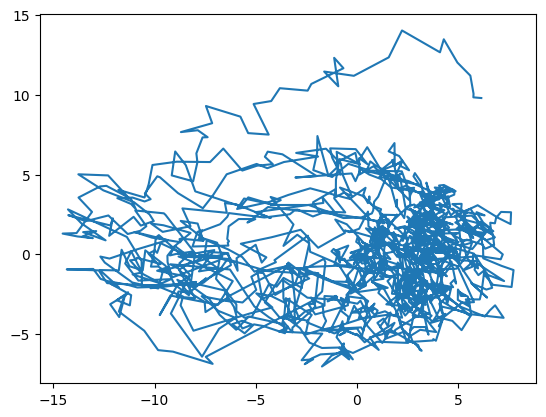

In [10]:
plt.plot(signal_reduced[:, 0], signal_reduced[:, 1])

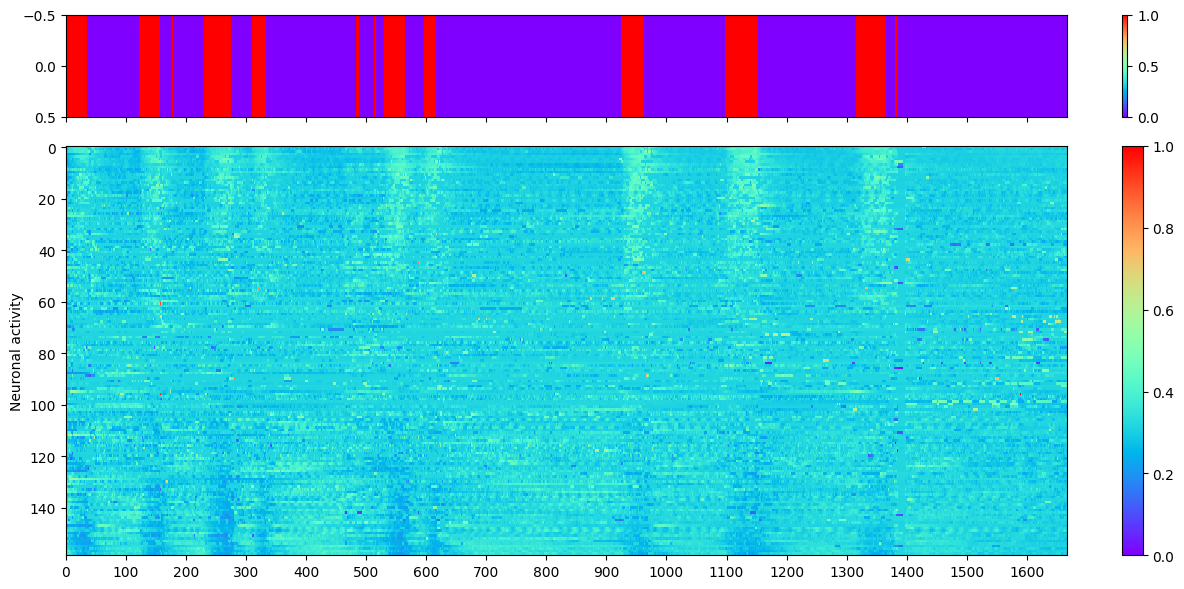

In [20]:
pc_contrib = pca.components_[0]
indices = np.argsort(pc_contrib)
signal_hm = signal.T[indices]
z_scores = (signal_hm - signal_hm.mean()) / signal_hm.std()
filtered = signal_hm[np.abs(z_scores) < 3]
signal_hm = ((signal_hm - signal_hm.min()) / (signal_hm.max() - signal_hm.min()))

reversals = (np.array(behavioral_data['reversal_events'].time_series['reversal_events'].data[:])).reshape(1667, 1).T

fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 4]})

im_bottom = ax_bottom.imshow(signal_hm, aspect='auto', cmap='rainbow', interpolation='nearest')
ax_bottom.set_ylabel("Neuronal activity")
ax_top.set_xticks(np.arange(0, len(signal), 100))
fig.colorbar(im_bottom, ax=ax_bottom, orientation='vertical', fraction=0.05)

im_top = ax_top.imshow(reversals, aspect='auto', cmap='rainbow' ,interpolation='nearest') #, extent=[signal_hm[0] - 0.5, signal_hm[-1] + 0.5, 0, 1]
fig.colorbar(im_top, ax=ax_top, orientation='vertical', fraction=0.05)

plt.tight_layout()
plt.show()


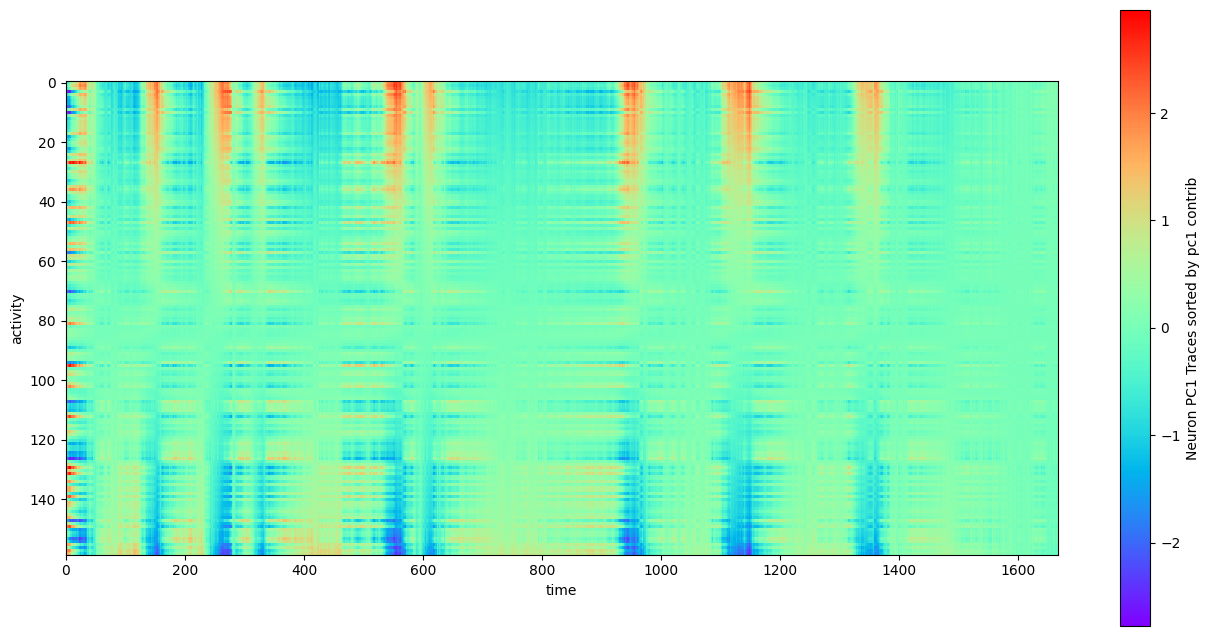

<Figure size 640x480 with 0 Axes>

In [12]:
signal_reconstructed = pca.inverse_transform(signal_reduced)

plt.figure(figsize=(16, 8))
plt.imshow(signal_reconstructed.T[indices], interpolation='nearest', cmap='rainbow', aspect=5)
plt.colorbar(label='Neuron PC1 Traces sorted by pc1 contrib')
plt.xlabel('time')
plt.ylabel('activity')
plt.show()
plt.tight_layout()

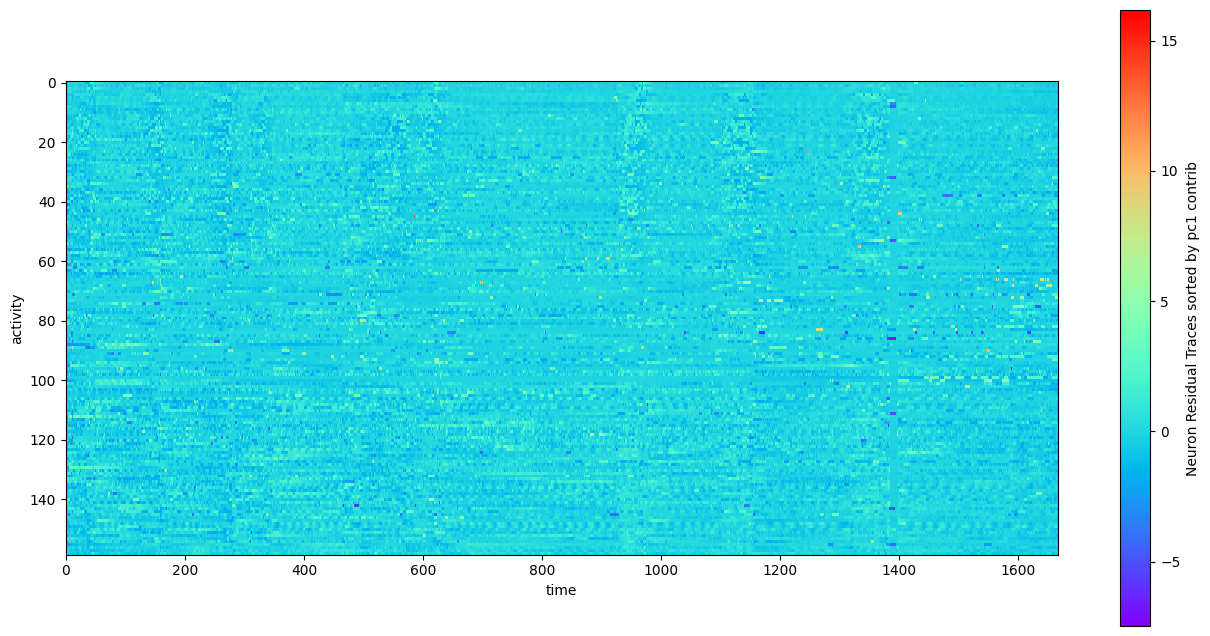

<Figure size 640x480 with 0 Axes>

In [13]:
signal_residual = signal - signal_reconstructed

plt.figure(figsize=(16, 8))
plt.imshow(signal_residual.T[indices], interpolation='nearest', cmap='rainbow', aspect=5)
plt.colorbar(label='Neuron Residual Traces sorted by pc1 contrib')
plt.xlabel('time')
plt.ylabel('activity')
plt.show()
plt.tight_layout()

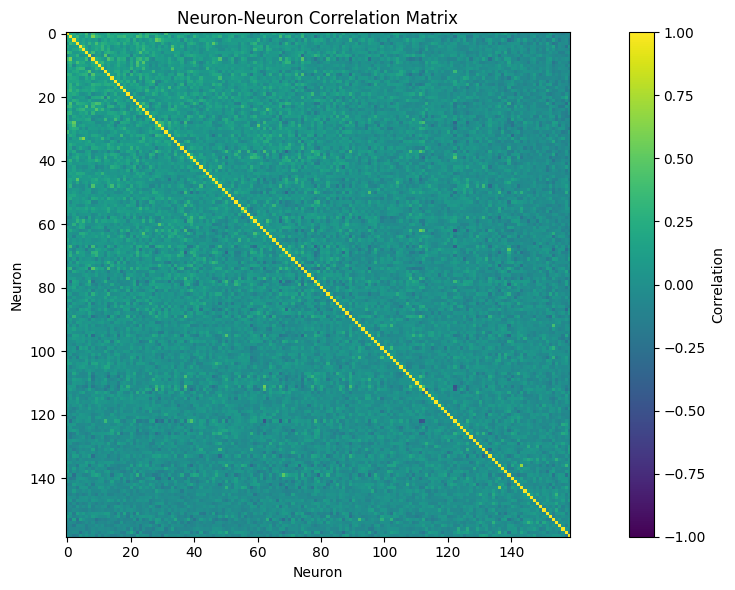

In [14]:
corr = np.corrcoef(signal_residual.T)
corr_sums = np.sum(corr, axis=1)
idxs = np.argsort(corr_sums)[::-1]

corr = corr[idxs][:, idxs]

plot_correlation_heatmap(corr)

In [15]:
pca_residual = PCA(n_components=2)
signal_residual_reduced = pca_residual.fit_transform(signal_residual)

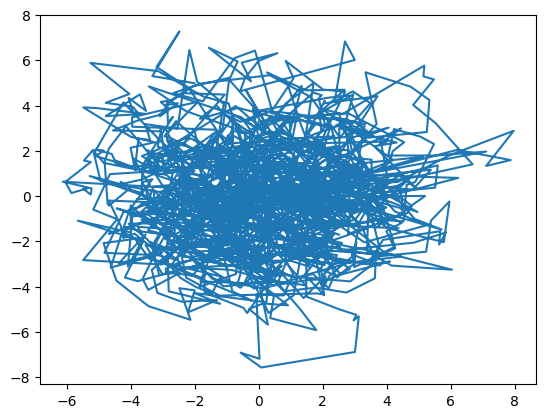

In [16]:
plt.plot(signal_residual_reduced[:, 0], signal_residual_reduced[:, 1])

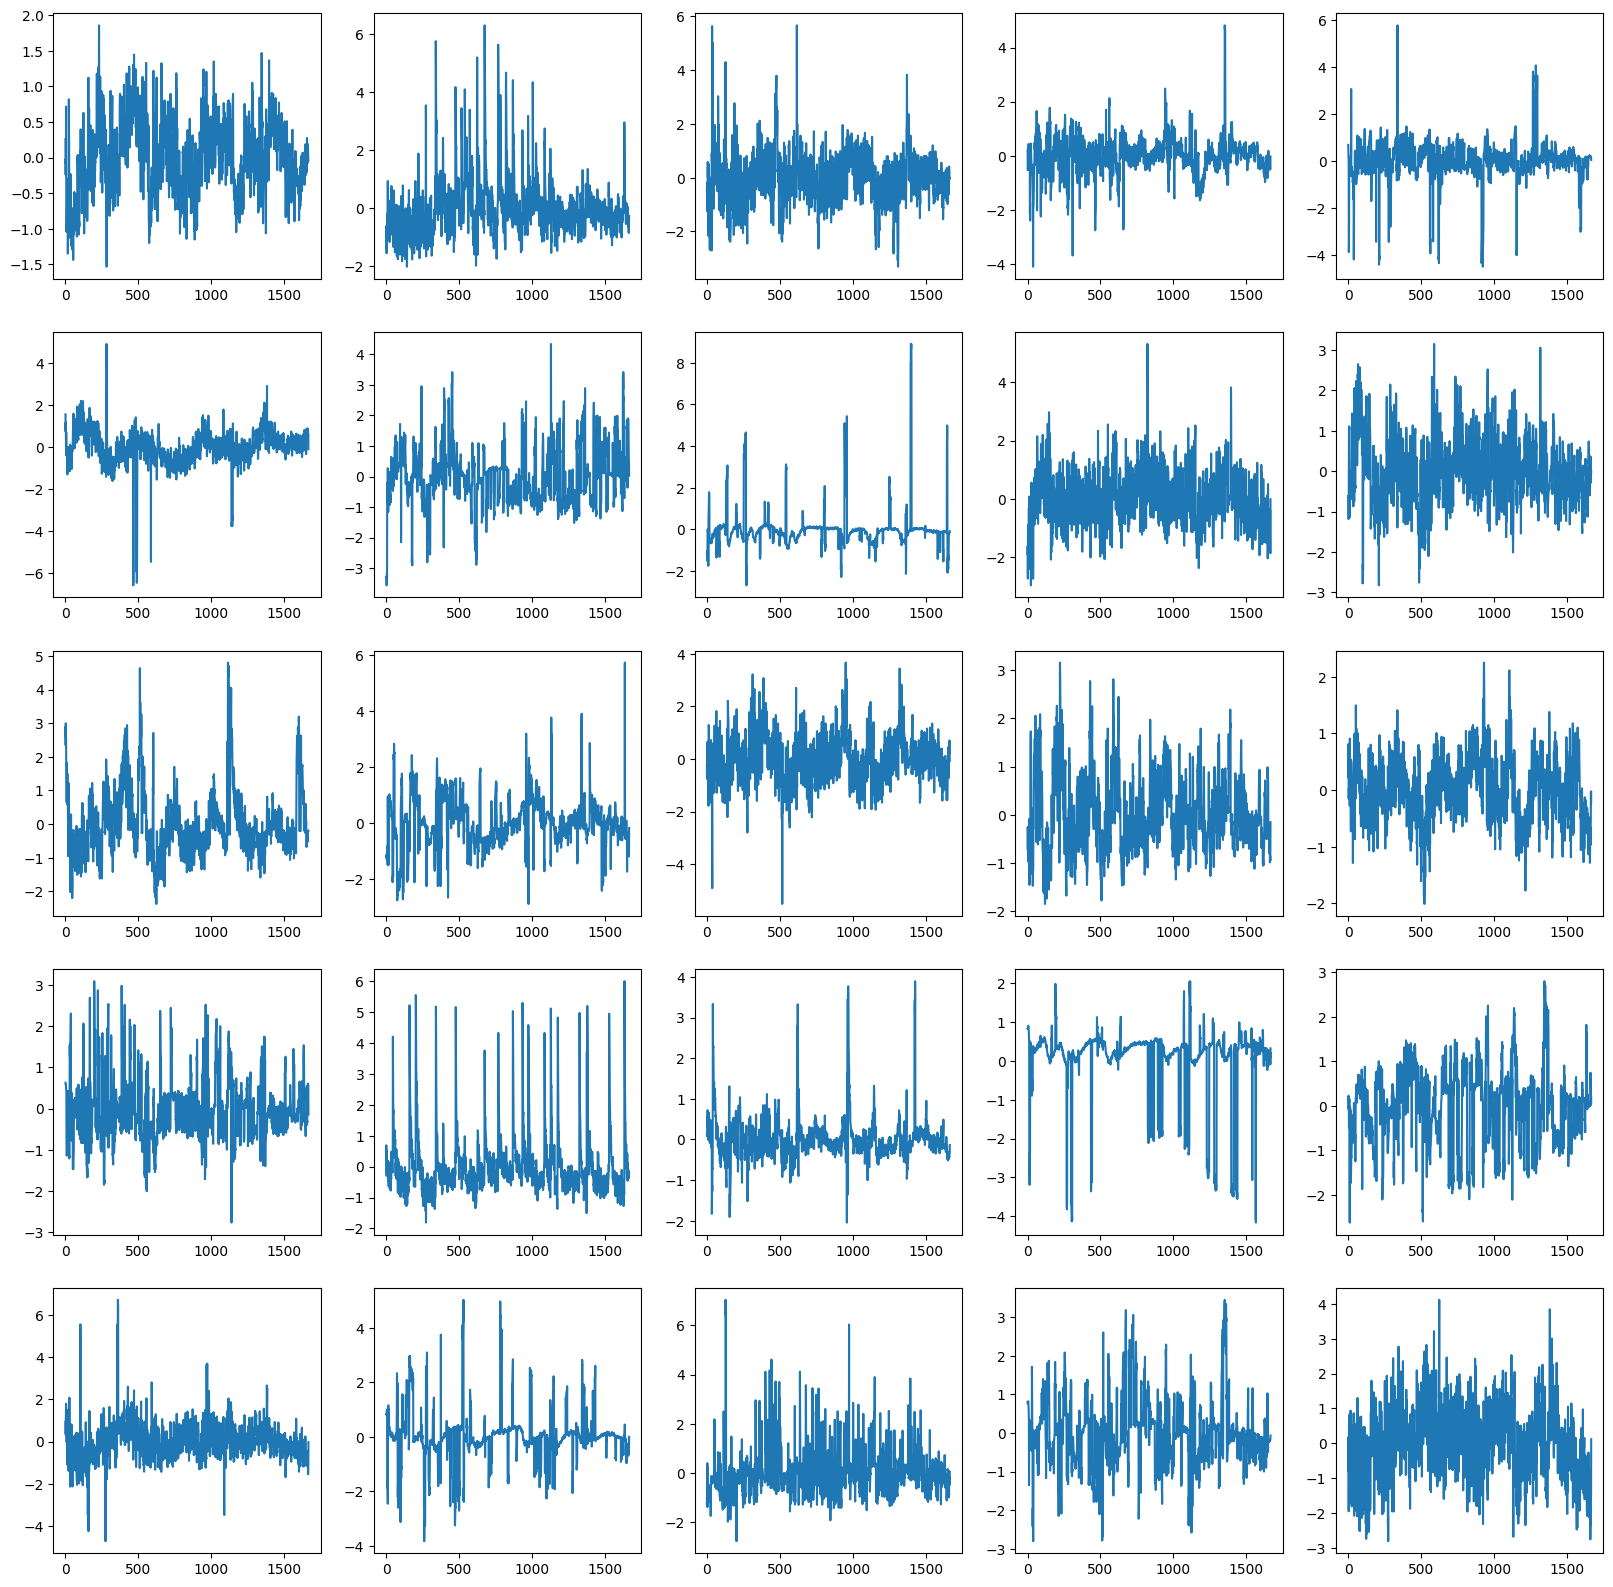

In [17]:
fig, axes = plt.subplots(5, 5, figsize=(20, 20))
for i in range(5*5):
	axes[i // 5, i % 5].plot(signal_residual[:2500, i])

In [18]:
blacklist = ['discrete_states', 'eigenworms', 'hilbert_amplitude', 'hilbert_carrier', 'hilbert_frequency', 'hilbert_phase', 'kymograph', 'stage_position']
for field1 in behavioral_data.keys():
	if field1 in blacklist:
		continue
	for field2 in behavioral_data.keys():
		if field2 in blacklist or field1 == field2:
			continue
		print(field1, field2)
		data1 = np.array(behavioral_data[field1].time_series[field1].data)
		data2 = np.array(behavioral_data[field2].time_series[field2].data)
		datas = np.stack((data1, data2))
		correl = np.corrcoef(datas)
		print(correl[0, 1])

angular_velocity body_curvature
-0.12379030144132418
angular_velocity head_curvature
-0.04006388196288226
angular_velocity reversal_events
0.9056766501523206
angular_velocity velocity
-0.9421879285930773
body_curvature angular_velocity
-0.12379030144132418
body_curvature head_curvature
0.457112190794047
body_curvature reversal_events
-0.1543304602275493
body_curvature velocity
0.18008282441533627
head_curvature angular_velocity
-0.04006388196288227
head_curvature body_curvature
0.457112190794047
head_curvature reversal_events
-0.08735340378374572
head_curvature velocity
0.07371075318926817
reversal_events angular_velocity
0.9056766501523206
reversal_events body_curvature
-0.15433046022754932
reversal_events head_curvature
-0.08735340378374572
reversal_events velocity
-0.9387031532963551
velocity angular_velocity
-0.9421879285930773
velocity body_curvature
0.18008282441533627
velocity head_curvature
0.07371075318926817
velocity reversal_events
-0.938703153296355
